# Phase 1 -- Aspect-Based Sentiment Analysis (ABSA)

**Goal:** Extract per-aspect sentiment from smartphone review text. Compare a DL approach (PyABSA / HuggingFace transformer) against an ML baseline (TF-IDF + Logistic Regression). The aspect-sentiment scores produced here become the multivariate input for Phase 2 temporal aggregation and Phase 3 drift detection.

**Pipeline:** Synonym-dict aspect detection -> Model-based sentiment classification -> Review-level long-format export

**Approach:**
- Seed-guided Aspect Polarity Classification (not open ATEPC)
- Hand-checked synonym dictionary for aspect localisation
- TF-IDF + one-hot aspect + single LR as ML baseline
- Evaluation on ~200 hand-labelled reviews from val/test splits

In [ ]:
# Self-contained bootstrap (WM9B7 AIDL FAQ compliance)
# Auto-runs upstream phase notebooks if their outputs are missing so this
# notebook is runnable end-to-end with no manual step. Set
# SENTINELDRIFT_SKIP_BOOTSTRAP=1 to bypass during interactive development.
import os, sys
from pathlib import Path

_nb_dir = Path(os.getcwd()).resolve()
_root = _nb_dir if (_nb_dir / "src" / "bootstrap.py").exists() else _nb_dir.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.bootstrap import ensure_inputs  # noqa: E402
ensure_inputs(for_phase="01_absa")


## 1. Setup & Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, sys, gc, json, hashlib, re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tqdm.auto import tqdm

import torch

# Paths (relative to repo root)
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(ROOT))

from src.utils import DATA_PROCESSED, MODELS_DIR, RESULTS_DIR
from src.absa.pyabsa_runner import (
# detect_aspects: synonym-based lexicon lookup; predict_*: PyABSA APC inference
    ASPECT_SYNONYMS, detect_aspects, inject_aspect_tags,
    predict_single, predict_batch, make_review_pk,
    SENTIMENT_SCORE_MAP,
)
from src.absa.tfidf_baseline import (
# TF-IDF+LR baseline: pair-based classifier (1 review x 1 aspect = 1 pair)
    TfidfAspectClassifier, CANONICAL_ASPECTS, LABELS,
    build_pair_dataset,
)

# Config
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

RESULTS_ABSA = RESULTS_DIR / "absa"
RESULTS_ABSA.mkdir(parents=True, exist_ok=True)
LABELS_DIR = ROOT / "data" / "labels"
LABELS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_ABSA = MODELS_DIR / "absa"
MODELS_ABSA.mkdir(parents=True, exist_ok=True)

CASE_STUDY_ASINS = Path(DATA_PROCESSED / "case_study_asins.txt").read_text().strip().split("\n")
print(f"Case study ASINs: {CASE_STUDY_ASINS}")
print(f"Canonical aspects ({len(CANONICAL_ASPECTS)}): {CANONICAL_ASPECTS}")

Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
Case study ASINs: ['B019BX7F86', 'B07HD2X91Q', 'B0178GE72K', 'B0178GE4FU', 'B00OL4DEMC']
Canonical aspects (9): ['audio', 'battery', 'build', 'camera', 'charging', 'connectivity', 'display', 'performance', 'software']


## 2. Data Loading & Temporal Coverage Verification

In [2]:
# Load clean dataset from Phase 0
df = pd.read_parquet(DATA_PROCESSED / "smartphone_reviews_clean.parquet")
print(f"Loaded {len(df):,} reviews, {df['parent_asin'].nunique():,} products")
print(f"Columns: {list(df.columns)}")
print()
print("Split distribution:")
print(df["split"].value_counts())

# ABSA text column: prefer combined (title + body) if available
TEXT_COL = "review_text_combined" if "review_text_combined" in df.columns else "review_text"
print(f"ABSA text column: '{TEXT_COL}'")

# Create stable review_pk
# SHA-256 hash of (user_id, asin, text, timestamp) as collision-resistant dedup key
df["review_pk"] = df.apply(
    lambda r: make_review_pk(
        str(r["user_id"]), str(r["parent_asin"]),
        str(r["review_text"]), str(r["timestamp"])
    ), axis=1,
)
assert df["review_pk"].is_unique, "review_pk collision detected!"
print(f"review_pk created ({df['review_pk'].nunique():,} unique)")

Loaded 318,361 reviews, 1,501 products
Columns: ['user_id', 'review_text', 'review_title', 'review_text_combined', 'rating', 'timestamp', 'parent_asin', 'verified_purchase', 'helpful_vote', 'product_title', 'split', 'store', 'categories', 'features', 'description', 'is_surge_day']

Split distribution:
split
train    304210
val       10488
test       3663
Name: count, dtype: int64
ABSA text column: 'review_text_combined'
review_pk created (318,361 unique)


In [3]:
# Filter to dense products (Phase 2/3 scope)
density = pd.read_csv(DATA_PROCESSED / "product_density.csv")
# Dense products: >=12 active months, >=5 reviews/month, <=6-month max gap
dense_asins = density[
    (density["active_months"] >= 12)
    & (density["avg_reviews_per_active_month"] >= 5)
    & (density["max_gap_months"] <= 6)
]["parent_asin"].tolist()

df_dense = df[df["parent_asin"].isin(dense_asins)].copy()
print(f"Dense products: {len(dense_asins)}")
print(f"Dense reviews: {len(df_dense):,}")
print(f"\nDense split distribution:")
print(df_dense["split"].value_counts())

Dense products: 338
Dense reviews: 149,227

Dense split distribution:
split
train    137561
val        8593
test       3073
Name: count, dtype: int64


=== Case Study ASIN Coverage ===
      ASIN                                            product  total  train  val  test
B019BX7F86 Huawei Nexus 6P unlocked smartphone, 32GB Gold (US   2092   2091    1     0
B07HD2X91Q Nokia 7.1 - Android 9.0 Pie - 64 GB - Dual Camera     338    336    1     1
B0178GE72K LG Nexus 5X Unlocked Smartphone - White 16GB (U.S.    482    481    1     0
B0178GE4FU LG Nexus 5X Unlocked Smartphone - Black 16GB (U.S.    209    207    2     0
B00OL4DEMC                  LG Tribute Black (Virgin Prepaid)    247    247    0     0

NOTE: Several case study ASINs have 0 val/test reviews (expected for discontinued phones).
Evaluation will use all dense products, not just case studies.


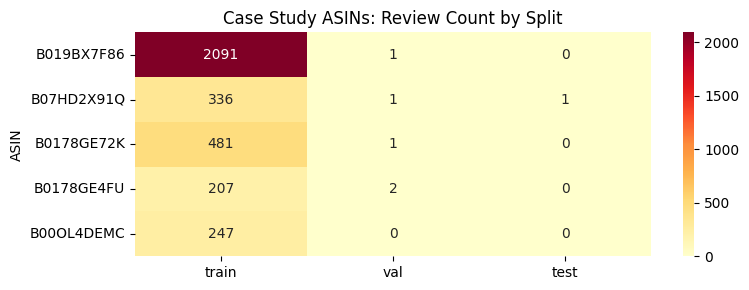


Limitation: Older case study products lack recent reviews for temporal
val/test sets. ABSA is evaluated on 84 dense (newer) products via CV.
Applying the model to older phones assumes temporal language transferability.


In [4]:
# Case study ASIN temporal coverage
# NOTE: Case study ASINs are older discontinued phones selected for documented
# hardware failures (drift detection ground truth). Near-zero val/test reviews
# is expected. ABSA evaluation uses the broader dense-product pool instead.
# Critical finding: most case study ASINs have near-zero val/test reviews.
# Evaluation will use the broader dense product pool, not just case studies.

case_coverage = []
for asin in CASE_STUDY_ASINS:
    sub = df[df["parent_asin"] == asin]
    title = sub["product_title"].iloc[0][:50] if len(sub) > 0 else "?"
    case_coverage.append({
        "ASIN": asin,
        "product": title,
        "total": len(sub),
        "train": len(sub[sub["split"] == "train"]),
        "val": len(sub[sub["split"] == "val"]),
        "test": len(sub[sub["split"] == "test"]),
    })
case_df = pd.DataFrame(case_coverage)
print("=== Case Study ASIN Coverage ===")
print(case_df.to_string(index=False))
print("\nNOTE: Several case study ASINs have 0 val/test reviews (expected for discontinued phones).")
print("Evaluation will use all dense products, not just case studies.")

# Temporal heatmap for case studies
fig, ax = plt.subplots(figsize=(8, 3))
heatmap_data = case_df[["ASIN", "train", "val", "test"]].set_index("ASIN")
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlOrRd", ax=ax)
ax.set_title("Case Study ASINs: Review Count by Split")
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "case_study_coverage.png", dpi=150)
plt.show()

print("\nLimitation: Older case study products lack recent reviews for temporal")
print("val/test sets. ABSA is evaluated on 84 dense (newer) products via CV.")
print("Applying the model to older phones assumes temporal language transferability.")

## 3. Aspect Lexicon Pilot (~20 Reviews)

Quick sanity check: does the synonym dictionary correctly detect aspects in real review text? We run this on train-only data to avoid contaminating the evaluation set.

In [5]:
# Sample 20 train reviews from dense products for lexicon pilot
pilot_sample = (
    df_dense[df_dense["split"] == "train"]
    .sample(n=20, random_state=SEED)
    .reset_index(drop=True)
)

print("=== Lexicon Pilot: 20 Train Reviews ===\n")
aspect_counter = Counter()
for i, row in pilot_sample.iterrows():
    text = row[TEXT_COL]
    # Synonym-based aspect detection: matches keywords from ASPECT_SYNONYMS dict
    hits = detect_aspects(text)
    aspects_found = [h["aspect"] for h in hits]
    aspect_counter.update(aspects_found)

    # Show first 200 chars of review + detected aspects
    preview = text[:200] + ("..." if len(text) > 200 else "")
    print(f"Review {i+1} (rating={row['rating']}):")
    print(f"  Text: {preview}")
    if hits:
        for h in hits:
            # Show the keyword in context
            s = max(0, h["start"] - 20)
            e = min(len(text), h["end"] + 20)
            ctx = text[s:e].replace("\n", " ")
            print(f"  -> [{h['aspect']}] keyword='{h['keyword']}' | context: '...{ctx}...'")
    else:
        print("  -> No aspects detected")
    print()

print("=== Aspect Detection Summary ===")
for asp in CANONICAL_ASPECTS:
    print(f"  {asp}: {aspect_counter.get(asp, 0)} mentions")
print(f"\nTotal reviews with >= 1 aspect: {sum(1 for i, r in pilot_sample.iterrows() if detect_aspects(r[TEXT_COL]))}/20")

=== Lexicon Pilot: 20 Train Reviews ===

Review 1 (rating=5):
  Text: Five Stars. Bought for hubby, he refuses to get a "smartphone"
  -> No aspects detected

Review 2 (rating=5):
  Text: Completely satisfied.. Phone is great..came as advertised new in box and with all the accessories mentioned above. Also it runs on the android lollipop platform. .my only thing is its only got 4gb of ...
  -> [software] keyword='android' | context: '...Also it runs on the android lollipop platform. ...'

Review 3 (rating=3):
  Text: Returned gift. Didn't have the phone long enough to give it a full review it was a gift
  -> No aspects detected

Review 4 (rating=4):
  Text: Unlocked Phone. The Phone was intended to use in Pakistan (as an Unlocked Phone) and its running good there. The phone displayed 64 GB memory on box and a confusing statement which let me believe that...
  -> [performance] keyword='memory' | context: '...one displayed 64 GB memory on box and a confus...'
  -> [display] keyword='disp

## 4. PyABSA / Transformer Zero-Shot Pilot (~50 Reviews)

Test the DL sentiment model on 50 train reviews. PyABSA APC is attempted first; if the checkpoint is incompatible with our transformers version, we fall back to a HuggingFace sentiment pipeline (cardiffnlp/twitter-roberta-base-sentiment-latest) applied to sentence-level context.

This pilot uses **train data only** -- evaluation data is untouched.


In [6]:
# DL Pilot: 50 train reviews
pilot_dl = (
    df_dense[df_dense["split"] == "train"]
    .sample(n=50, random_state=SEED + 1)
    .reset_index(drop=True)
)

print("=== DL Sentiment Pilot: 50 Train Reviews ===\n")
pilot_results = []
for i, row in tqdm(pilot_dl.iterrows(), total=len(pilot_dl), desc="DL pilot"):
    text = row[TEXT_COL]
    # PyABSA APC: detect aspects via synonyms, tag with [B-ASP]/[E-ASP], run sentiment clf
    preds = predict_single(text)
    for pred in preds:
        pred["review_idx"] = i
        pred["rating"] = row["rating"]
        pilot_results.append(pred)

pilot_df = pd.DataFrame(pilot_results)
if len(pilot_df) > 0:
    print(f"\nPilot produced {len(pilot_df)} aspect-sentiment predictions "
          f"from {len(pilot_dl)} reviews")
    print(f"Source model: {pilot_df['source_model'].value_counts().to_dict()}")
    print(f"\nSentiment distribution:")
    print(pilot_df["sentiment_label"].value_counts())
    print(f"\nAspect distribution:")
    print(pilot_df["canonical_aspect"].value_counts())
else:
    print("WARNING: No aspects detected in pilot. Check synonym dictionary.")

=== DL Sentiment Pilot: 50 Train Reviews ===



DL pilot:   0%|          | 0/50 [00:00<?, ?it/s]

<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
c:\Users\alexi\anaconda3\envs\aidl\Lib\site-packages\torch\jit\_script.py:1480: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[2026-04-13 15:42:50] (2.4.2) PyABSA(2.4.2): If your code crashes on Colab, please use the GPU runtime. Then run "pip install pyabsa[dev] -U" and restart the kernel.
Or if it does not work, you can use v1.x versions, e.g., pip install pyabsa<2.0 -U




Try to downgrade transformers<=4.29.0.




[2026-04-13 15:42:51] (2.4.2) ********** Available APC model checkpoints for Version:2.4.2 (this version) **********
[2026-04-13 15:42:51] (2.4.2) ********** Available APC model checkpoints for Version:2.4.2 (this version) **********
[2026-04-13 15:42:51] (2.4.2) Downloading checkpoint:english 
[2026-04-13 15:42:51] (2.4.2) Notice: The pretrained model are used for testing, it is recommended to train the model on your own custom datasets
[2026-04-13 15:42:51] (2.4.2) Checkpoint already downloaded, skip
[2026-04-13 15:42:51] (2.4.2) Load sentiment classifier from checkpoints\APC_ENGLISH_CHECKPOINT\fast_lsa_t_v2_English_acc_82.21_f1_81.81
[2026-04-13 15:42:51] (2.4.2) config: checkpoints\APC_ENGLI

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[2026-04-13 15:42:56] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: Worst item ever bought!!! Worked for 2 days and [B-ASP]screen[E-ASP] went funny!!! Rip off!


We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


[2026-04-13 15:42:56] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: I need the apps to work. 1 When I received a [B-ASP]picture[E-ASP] I will see it and then it get blurry and then I cannot open it anymore. 2 No word document is opening, Although I have the app loaded.
[2026-04-13 15:42:57] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: 1 When I received a picture I will see it and then it get blurry and then I cannot open it anymore. 2 No word document is opening, Although I have the [B-ASP]app[E-ASP] loaded.
[2026-04-13 15:42:57] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: I have the black Razor, my wife has the silver. The biggest complaint we both have is the [B-ASP]volume[E-ASP] of the ear speaker. My sister-in-law can't use the phone at all because of this.
[2026-04-13 15:42:57] (2.4.2) Warning: ref

In [7]:
# Pilot analysis: sentiment vs star rating sanity check
if len(pilot_df) > 0:
    # Show sample predictions
    print("=== Sample Predictions (first 15) ===\n")
    sample_show = pilot_df.head(15)
    for _, pred in sample_show.iterrows():
        ridx = pred["review_idx"]
        text = pilot_dl.iloc[ridx][TEXT_COL][:120]
        print(f"  [{pred['canonical_aspect']}] {pred['sentiment_label']} "
              f"(conf={pred['confidence']:.2f}) | star={pred['rating']} | "
              f"'{text}...'")

    # Aggregate: mean sentiment_score per review vs star rating
    review_agg = pilot_df.groupby("review_idx").agg(
        mean_sent=("sentiment_score", "mean"),
        n_aspects=("canonical_aspect", "count"),
    )
    review_agg = review_agg.join(
        pilot_dl[["rating"]].rename_axis("review_idx")
    )
    if len(review_agg) > 5:
        rho, pval = spearmanr(review_agg["mean_sent"], review_agg["rating"])
        print(f"\nSpearman(mean_aspect_sentiment, star_rating) = {rho:.3f}, p = {pval:.4f}")
        if rho > 0:
            print("Positive correlation -- aspect sentiments directionally agree with star ratings.")
        else:
            print("WARNING: Negative/zero correlation. Inspect model predictions carefully.")

    # Failure mode categorisation
    print(f"\n=== Failure Mode Summary ===")
    pos_with_low_star = pilot_df[(pilot_df["sentiment_label"] == "positive") & (pilot_df["rating"] <= 2)]
    neg_with_high_star = pilot_df[(pilot_df["sentiment_label"] == "negative") & (pilot_df["rating"] >= 4)]
    print(f"  Positive sentiment + low star (1-2): {len(pos_with_low_star)}")
    print(f"  Negative sentiment + high star (4-5): {len(neg_with_high_star)}")
    print(f"  (These may be valid -- aspects can disagree with overall rating)")

=== Sample Predictions (first 15) ===

  [display] negative (conf=0.63) | star=1 | 'Don't waste your money even if you think it seems cheap. Worst item ever bought!!! Worked for 2 days and screen went fun...'
  [camera] negative (conf=0.71) | star=4 | 'I need the apps to work. 1 When I received a picture I will see it and then it get blurry and then I cannot open it anym...'
  [software] negative (conf=0.68) | star=4 | 'I need the apps to work. 1 When I received a picture I will see it and then it get blurry and then I cannot open it anym...'
  [audio] negative (conf=0.99) | star=3 | 'Can you hear me now?. In March my wife and I switched to Cingular and decided to get the hip bling bling phone The Razor...'
  [display] neutral (conf=0.97) | star=3 | 'Can you hear me now?. In March my wife and I switched to Cingular and decided to get the hip bling bling phone The Razor...'
  [build] positive (conf=0.97) | star=3 | 'Can you hear me now?. In March my wife and I switched to Cingular and d

## 5. Gold Label Set -- Generation, Loading & Analysis

We generate a stratified sample of ~200 reviews from val+test splits across all 84 dense products. These are pseudo-labelled using the DL model and exported for human correction.

**If no labels have been human-corrected,** the notebook falls back to star-rating proxy labels (1-2=negative, 3=neutral, 4-5=positive). This produces approximate metrics only. **Team members: correct the gold labels in `data/labels/absa_gold_labels.csv` and set `human_corrected=True` before treating metrics as final.**

**Labelling format:** `review_pk, review_text, canonical_aspect, sentiment_label` where sentiment is one of {positive, negative, neutral}.

**Limitation acknowledged:** No double-labelling or inter-annotator agreement due to deadline constraints.

In [8]:
# Generate labelling candidate set
# Strategy: sample from val+test across all dense products, stratified by
# rating band (1-2, 3, 4-5) to ensure sentiment diversity.

GOLD_LABEL_PATH = LABELS_DIR / "absa_gold_labels.csv"

eval_pool = df_dense[df_dense["split"].isin(["val", "test"])].copy()
print(f"Evaluation pool: {len(eval_pool):,} reviews from val+test of dense products")

# Stratified sample by rating band
# Stratify by rating band to ensure low/mid/high sentiment diversity in gold set
eval_pool["rating_band"] = pd.cut(
    eval_pool["rating"], bins=[0, 2, 3, 5], labels=["low", "mid", "high"]
)

# Sample ~200, proportional to rating band but with floor of 30 per band
target_n = 200
band_counts = eval_pool["rating_band"].value_counts()
samples_per_band = {}
for band in ["low", "mid", "high"]:
    available = band_counts.get(band, 0)
    samples_per_band[band] = min(max(30, target_n // 3), available)

label_candidates = pd.concat([
    eval_pool[eval_pool["rating_band"] == band].sample(
        n=samples_per_band[band], random_state=SEED
    )
    for band in ["low", "mid", "high"]
    if samples_per_band[band] > 0
]).reset_index(drop=True)

print(f"\nLabel candidates: {len(label_candidates)} reviews")
print(f"Rating band distribution:")
print(label_candidates["rating_band"].value_counts())
print(f"Split distribution:")
print(label_candidates["split"].value_counts())

Evaluation pool: 11,666 reviews from val+test of dense products

Label candidates: 198 reviews
Rating band distribution:
rating_band
low     66
mid     66
high    66
Name: count, dtype: int64
Split distribution:
split
val     144
test     54
Name: count, dtype: int64


In [9]:
# Auto-generate pseudo-labels using the DL model
# These serve as PREANNOTATION for human correction, not as ground truth.

FORCE_REGENERATE_GOLD = False  # Set True to regenerate; False to keep human corrections  # Set False after first regen to keep human edits

if FORCE_REGENERATE_GOLD or not GOLD_LABEL_PATH.exists():
    if GOLD_LABEL_PATH.exists():
        # Archive the old file before overwriting
        import shutil
        archive_path = GOLD_LABEL_PATH.with_suffix(".csv.bak")
        shutil.copy2(GOLD_LABEL_PATH, archive_path)
        print(f"Archived old gold labels to {archive_path}")

    print("Generating pseudo-labels for human correction...")
    pseudo_labels = []
    for i, row in tqdm(label_candidates.iterrows(), total=len(label_candidates),
                       desc="Pseudo-labelling"):
        text = row[TEXT_COL]
        # PyABSA-only inference (no HF fallback) to generate preannotation for human review
        preds = predict_single(text, allow_hf_fallback=False)
        for pred in preds:
            pseudo_labels.append({
                "review_pk": row["review_pk"],
                "review_text": text[:500],  # truncate for readability
                "parent_asin": row["parent_asin"],
                "split": row["split"],
                "rating": row["rating"],
                "canonical_aspect": pred["canonical_aspect"],
                "keyword_matched": pred["keyword"],
                "sentiment_label": pred["sentiment_label"],
                "confidence": pred["confidence"],
                "human_corrected": False,
                "aspect_valid": True,  # annotators set False for bad detections
                "source_model": pred.get("source_model", "unknown"),
                "generation_timestamp": __import__("datetime").datetime.now().isoformat(),
            })

    pseudo_df = pd.DataFrame(pseudo_labels)
    pseudo_df.to_csv(GOLD_LABEL_PATH, index=False)
    print(f"\nPseudo-labels saved to {GOLD_LABEL_PATH}")
    print(f"Total triplets: {len(pseudo_df)}")
    print(f"Aspect distribution:")
    print(pseudo_df["canonical_aspect"].value_counts())
    print(f"\nIMPORTANT: Review and correct these labels in the CSV before proceeding.")
    print("Set 'human_corrected' to True for rows you have reviewed.")
else:
    print(f"Gold labels already exist at {GOLD_LABEL_PATH}")
    print("Loading existing labels...")


Gold labels already exist at C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\labels\absa_gold_labels.csv
Loading existing labels...


All 216 labels are human-corrected. Using full gold set.

=== Gold Label Set  ===
Total triplets: 216
Unique reviews: 129

Aspect support:
canonical_aspect
battery         62
display         43
performance     25
audio           23
charging        16
software        15
camera          15
connectivity     9
build            8
Name: count, dtype: int64

Sentiment distribution:
sentiment_label
negative    130
positive     57
neutral      29
Name: count, dtype: int64
Excluding 21 rows with aspect_valid=False

Val labels: 153 triplets (93 reviews)
Test labels: 42 triplets (30 reviews)


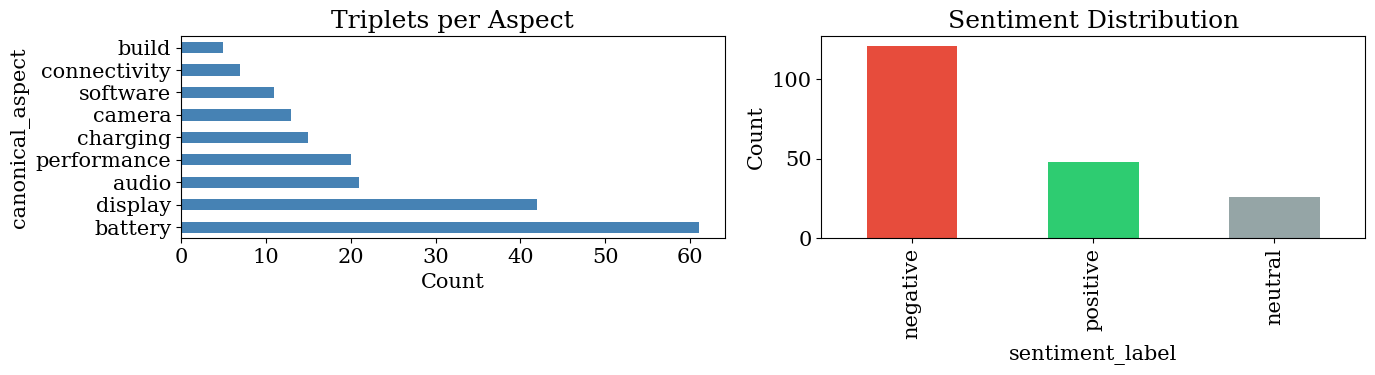

In [10]:
# Load and analyse gold labels
gold_raw = pd.read_csv(GOLD_LABEL_PATH)
n_corrected = int(gold_raw["human_corrected"].sum())
n_total = len(gold_raw)

USING_PROXY_LABELS = (n_corrected == 0)

if USING_PROXY_LABELS:
    # =========================================================================
    #  NO HUMAN-CORRECTED LABELS, FALLING BACK TO STAR-RATING PROXY
    # =========================================================================
    print("=" * 72)
    print("!!  WARNING: STAR-RATING PROXY LABELS IN USE  !!")
    print("=" * 72)
    print(f"  Gold label file has {n_total} triplets but 0 are human-corrected.")
    print(f"  ALL downstream evaluation metrics are APPROXIMATE.")
    print(f"  Star ratings (1-2=neg, 3=neutral, 4-5=pos) replace gold sentiment.")
    print()
    print(f"  >>> To fix: open {GOLD_LABEL_PATH}")
    print(f"  >>> Correct 'sentiment_label' and set 'human_corrected' = True")
    print(f"  >>> Then re-run this notebook for real evaluation metrics.")
    print("=" * 72)

    # Build proxy gold from the same candidate reviews, using star ratings
    STAR_SENTIMENT_MAP = {1: "negative", 2: "negative", 3: "neutral",
                          4: "positive", 5: "positive"}
    proxy_rows = []
    for _, row in gold_raw.iterrows():
        proxy_rows.append({
            "review_pk": row["review_pk"],
            "review_text": row["review_text"],
            "parent_asin": row["parent_asin"],
            "split": row["split"],
            "rating": row["rating"],
            "canonical_aspect": row["canonical_aspect"],
            "keyword_matched": row.get("keyword_matched", ""),
            "sentiment_label": STAR_SENTIMENT_MAP.get(int(row["rating"]), "neutral"),
            "confidence": 1.0,
            "human_corrected": False,
        })
    gold = pd.DataFrame(proxy_rows)
    print(f"\nProxy gold labels: {len(gold)} triplets (star-rating derived)")

elif n_corrected < n_total:
    print(f"WARNING: Only {n_corrected}/{n_total} labels are human-corrected.")
    print("Using ONLY the human-corrected labels for evaluation.")
    gold = gold_raw[gold_raw["human_corrected"] == True].copy()
else:
    print(f"All {n_total} labels are human-corrected. Using full gold set.")
    gold = gold_raw.copy()

# Analysis
print(f"\n=== Gold Label Set {'(PROXY)' if USING_PROXY_LABELS else ''} ===")
print(f"Total triplets: {len(gold)}")
print(f"Unique reviews: {gold['review_pk'].nunique()}")

print(f"\nAspect support:")
aspect_support = gold["canonical_aspect"].value_counts()
print(aspect_support)

print(f"\nSentiment distribution:")
print(gold["sentiment_label"].value_counts())

# Split gold into val (for tuning) and test (for evaluation)
# Exclude rows where human reviewer flagged aspect as invalid
if "aspect_valid" in gold.columns:
    n_invalid = (~gold["aspect_valid"].astype(bool)).sum()
    if n_invalid > 0:
        print(f"Excluding {n_invalid} rows with aspect_valid=False")
        gold = gold[gold["aspect_valid"].astype(bool)].reset_index(drop=True)

sentiment_labels = ["positive", "negative", "neutral"]

gold_val = gold[gold["split"] == "val"]
gold_test = gold[gold["split"] == "test"]
gold_eval = gold_test.copy()  # Use test split for ALL model evaluation
print(f"\nVal labels: {len(gold_val)} triplets ({gold_val['review_pk'].nunique()} reviews)")
print(f"Test labels: {len(gold_test)} triplets ({gold_test['review_pk'].nunique()} reviews)")

# Flag low-support aspects
for asp in CANONICAL_ASPECTS:
    n_test = len(gold_test[gold_test["canonical_aspect"] == asp])
    if n_test < 15:
        print(f"  WARNING: '{asp}' has only {n_test} test instances -- interpret F1 with caution")

# Visualise support
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
title_suffix = " (STAR-RATING PROXY)" if USING_PROXY_LABELS else ""
gold["canonical_aspect"].value_counts().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title(f"Triplets per Aspect{title_suffix}")
axes[0].set_xlabel("Count")
gold["sentiment_label"].value_counts().plot.bar(ax=axes[1], color=["#e74c3c", "#2ecc71", "#95a5a6"])
axes[1].set_title(f"Sentiment Distribution{title_suffix}")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "gold_label_distribution.png", dpi=150)
plt.show()


## 6. TF-IDF + LR Baseline Training

ML baseline using TF-IDF features (word 1-2 grams + char_wb 3-5 grams) concatenated with one-hot aspect encoding. Single balanced LogisticRegression classifier predicting {none, positive, negative, neutral}.

**Training strategy:** If human-corrected gold labels exist, the classifier is trained on those (few-shot). Otherwise, it is trained on **star-rating-derived labels** (1-2=neg, 3=neutral, 4-5=pos) with lexicon-detected aspects. This ensures an independent ML baseline -- NOT trained on DL model outputs.

Temporal holdout evaluation (n=42) is in Appendix A. **Primary evaluation uses 5-fold CV in Section 7.**

**Note on TF-IDF "none" predictions:** The TF-IDF baseline is a 4-class classifier (none/positive/negative/neutral). Training data includes "none" pairs for absent aspects (~8:1 imbalance). Despite class_weight="balanced", the model defaults to "none" for ambiguous aspect-text pairs. This architectural limitation -- inability to link sentiment to specific aspects via bag-of-words features -- is exactly what motivates the DL approach.

In [11]:
# Build training data for TF-IDF+LR baseline
# Strategy: use human-corrected gold labels if available (few-shot).
# Otherwise fall back to star-rating-derived labels (fully independent of DL).

if not USING_PROXY_LABELS and len(gold_val) > 0:
    # Gold-label path: use corrected val labels for training
    print("Building TF-IDF+LR training data from human-corrected gold labels...")
    train_pairs = []
    for _, row in gold_val.iterrows():
        text_match = df[df["review_pk"] == row["review_pk"]]
        text = text_match[TEXT_COL].iloc[0] if len(text_match) > 0 else ""
        train_pairs.append({
            "review_text": text,
            "canonical_aspect": row["canonical_aspect"],
            "label": row["sentiment_label"],
        })
    # Add "none" pairs for absent aspects
    for pk in gold_val["review_pk"].unique():
        gold_aspects = set(gold_val[gold_val["review_pk"] == pk]["canonical_aspect"])
        text_match = df[df["review_pk"] == pk]
        text = text_match[TEXT_COL].iloc[0] if len(text_match) > 0 else ""
        for asp in CANONICAL_ASPECTS:
            if asp not in gold_aspects:
                train_pairs.append({"review_text": text, "canonical_aspect": asp, "label": "none"})

    train_pairs_df = pd.DataFrame(train_pairs)
    print(f"Training pairs (gold): {len(train_pairs_df):,}")
    LR_TRAIN_SOURCE = "gold_labels"
else:
    # Star-rating fallback: independent of DL model
    print("Building TF-IDF+LR training data from STAR-RATING labels (independent of DL)...")
    STAR_SENTIMENT_MAP_TRAIN = {1: "negative", 2: "negative", 3: "neutral",
                                4: "positive", 5: "positive"}
    train_subset = df_dense[df_dense["split"] == "train"].sample(
        n=min(5000, len(df_dense[df_dense["split"] == "train"])),
        random_state=SEED,
    ).reset_index(drop=True)

    train_pairs = []
    for i, row in tqdm(train_subset.iterrows(), total=len(train_subset),
                       desc="Building train pairs"):
        text = row[TEXT_COL]
        hits = detect_aspects(text)
        hit_aspects = {h["aspect"] for h in hits}
        star_label = STAR_SENTIMENT_MAP_TRAIN.get(int(row["rating"]), "neutral")

        # Pair expansion: each review generates 9 rows (one per canonical aspect)
        for aspect in CANONICAL_ASPECTS:
            if aspect in hit_aspects:
                label = star_label  # use star rating as sentiment proxy
                # Star rating as proxy label when no human-corrected gold exists
            else:
                label = "none"
            train_pairs.append({
                "review_text": text,
                "canonical_aspect": aspect,
                "label": label,
            })

    train_pairs_df = pd.DataFrame(train_pairs)
    LR_TRAIN_SOURCE = "star_rating_proxy"
    print(f"\nTraining pairs (star-rating): {len(train_pairs_df):,}")

print(f"Label distribution:")
print(train_pairs_df["label"].value_counts())
print(f"\nTraining source: {LR_TRAIN_SOURCE}")

Building TF-IDF+LR training data from human-corrected gold labels...
Training pairs (gold): 837
Label distribution:
label
none        684
negative     92
positive     37
neutral      24
Name: count, dtype: int64

Training source: gold_labels


In [12]:
# Train TF-IDF+LR classifier
print("Training TF-IDF + LR pair classifier...")
tfidf_clf = TfidfAspectClassifier(max_features=10000)

# Build val pairs from gold_val for hyperparameter tuning
# (only if we didn't already use gold_val for training)
if LR_TRAIN_SOURCE == "star_rating_proxy" and len(gold_val) > 0:
    val_pairs = []
    for _, row in gold_val.iterrows():
        text_match = df[df["review_pk"] == row["review_pk"]]
        text = text_match["review_text"].iloc[0] if len(text_match) > 0 else ""
        val_pairs.append({
            "review_text": text,
            "canonical_aspect": row["canonical_aspect"],
            "label": row["sentiment_label"],
        })
    # Add "none" pairs for aspects not in gold_val for these reviews
    for pk in gold_val["review_pk"].unique():
        gold_aspects = set(gold_val[gold_val["review_pk"] == pk]["canonical_aspect"])
        text_match = df[df["review_pk"] == pk]
        text = text_match["review_text"].iloc[0] if len(text_match) > 0 else ""
        for asp in CANONICAL_ASPECTS:
            if asp not in gold_aspects:
                val_pairs.append({"review_text": text, "canonical_aspect": asp, "label": "none"})
    val_pairs_df = pd.DataFrame(val_pairs)
else:
    val_pairs_df = pd.DataFrame()
    print("No separate val set available -- training without val-based C tuning.")

# .train() tries multiple C values on val data and picks best macro-F1
train_metrics = tfidf_clf.train(
    texts=train_pairs_df["review_text"].tolist(),
    aspects=train_pairs_df["canonical_aspect"].tolist(),
    labels=train_pairs_df["label"].tolist(),
    val_texts=val_pairs_df["review_text"].tolist() if len(val_pairs_df) > 0 else None,
    val_aspects=val_pairs_df["canonical_aspect"].tolist() if len(val_pairs_df) > 0 else None,
    val_labels=val_pairs_df["label"].tolist() if len(val_pairs_df) > 0 else None,
)
print(f"Training complete: {train_metrics}")

# Save model
tfidf_clf.save(MODELS_ABSA / "tfidf_lr")
print(f"Model saved to {MODELS_ABSA / 'tfidf_lr'}")

Training TF-IDF + LR pair classifier...
No separate val set available -- training without val-based C tuning.
Training complete: {'C': 1.0}
Model saved to C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\models\absa\tfidf_lr


## 7. Cross-Validated Evaluation (Primary)

The temporal holdout evaluation above (n=42 test triplets) is underpowered: 5 of 9 aspects have fewer than 5 samples, and a single misclassification swings Macro F1 by ~11%. For a robust head-to-head comparison, we use **Stratified Grouped k-Fold** cross-validation on all 195 valid gold triplets.

**Why this is methodologically correct:**
- PyABSA is zero-shot (never trained on our data), so all 195 valid gold triplets are equally valid test data
- TF-IDF+LR trains on each fold's training portion
- Both models are evaluated on the **exact same test instances** per fold -- fair comparison
- Folds are grouped by `review_pk` to prevent leakage from multi-aspect reviews
- Stratified by aspect+sentiment to ensure balanced coverage across folds

All three models independently recommended this design. The temporal holdout is retained in Appendix A as a secondary robustness check.

**Splitting strategy:** Our pipeline uses two distinct approaches: (1) StratifiedGroupKFold CV for ABSA evaluation on limited gold labels (n=195), maximizing statistical power; (2) Per-product temporal splitting for downstream LSTM-AE drift detection on the full 146K corpus, ensuring all case study products are represented across time.

In [13]:
# Cross-validated evaluation: StratifiedGroupKFold on all gold labels
from sklearn.model_selection import StratifiedGroupKFold

# Use all valid gold labels (aspect_valid=True), both val and test splits
gold_cv = gold.copy()  # 'gold' already has aspect_valid filtering from cell 15
print(f"Cross-validation pool: {len(gold_cv)} triplets from "
      f"{gold_cv['review_pk'].nunique()} reviews")

# Merge full review text
gold_cv = gold_cv.merge(
    df[["review_pk", TEXT_COL]].drop_duplicates("review_pk"),
    on="review_pk", how="left", suffixes=("_trunc", ""),
)

# Stratification key: aspect + sentiment combo
gold_cv["strat_key"] = (gold_cv["canonical_aspect"] + "_"
                         + gold_cv["sentiment_label"])

# StratifiedGroupKFold: groups=review_pk, stratify=strat_key, k=5
N_SPLITS = 5
# Group-aware CV: groups=review_pk prevents same review leaking into both train and test
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True,
# Stratify on aspect+sentiment combo to preserve label distribution per fold
                             random_state=SEED)
groups = gold_cv["review_pk"]

dl_oof_preds = []    # out-of-fold DL predictions
lr_oof_preds = []    # out-of-fold LR predictions
y_true_oof = []      # out-of-fold true labels
review_pks_oof = []  # for review-grouped bootstrap
aspects_oof = []     # for per-aspect analysis

print(f"Running {N_SPLITS}-fold cross-validation...")
print("=" * 60)

for fold_idx, (train_idx, test_idx) in enumerate(
    sgkf.split(gold_cv, gold_cv["strat_key"], groups)
):
    train_fold = gold_cv.iloc[train_idx]
    test_fold = gold_cv.iloc[test_idx]

    n_train_reviews = train_fold["review_pk"].nunique()
    n_test_reviews = test_fold["review_pk"].nunique()

    # Verify no review leakage
    train_pks = set(train_fold["review_pk"])
    test_pks = set(test_fold["review_pk"])
    # Sanity check: no review appears in both train and test within a fold
    assert len(train_pks & test_pks) == 0, "Review leakage detected!"

    print(f"\nFold {fold_idx + 1}/{N_SPLITS}: "
          f"train={len(train_fold)} triplets ({n_train_reviews} reviews), "
          f"test={len(test_fold)} triplets ({n_test_reviews} reviews)")

    # PyABSA (zero-shot): predict on test fold reviews
    test_reviews = test_fold.drop_duplicates("review_pk")
    dl_preds_fold = []
    for _, row in test_reviews.iterrows():
        preds = predict_single(row[TEXT_COL])
        for pred in preds:
            pred["review_pk"] = row["review_pk"]
        dl_preds_fold.extend(preds)

    dl_preds_fold_df = pd.DataFrame(dl_preds_fold)

    # Match DL predictions to gold labels
    test_matched = test_fold[["review_pk", "canonical_aspect",
                               "sentiment_label"]].merge(
        dl_preds_fold_df[["review_pk", "canonical_aspect",
                          "sentiment_label"]],
        on=["review_pk", "canonical_aspect"],
        how="left",
        suffixes=("_gold", "_pred"),
    )
    test_matched["sentiment_label_pred"] = (
        test_matched["sentiment_label_pred"].fillna("none")
    )
    dl_fold_preds = test_matched["sentiment_label_pred"].tolist()

    # TF-IDF+LR: train on train fold, predict on test fold
    lr_train_pairs = []
    for pk in train_fold["review_pk"].unique():
        pk_rows = train_fold[train_fold["review_pk"] == pk]
        text = pk_rows[TEXT_COL].iloc[0]
        gold_aspects = set(pk_rows["canonical_aspect"])
        for _, row in pk_rows.iterrows():
            lr_train_pairs.append({
                "review_text": text,
                "canonical_aspect": row["canonical_aspect"],
                "label": row["sentiment_label"],
            })
        for asp in CANONICAL_ASPECTS:
            if asp not in gold_aspects:
                lr_train_pairs.append({
                    "review_text": text,
                    "canonical_aspect": asp,
                    "label": "none",
                })

    lr_train_df = pd.DataFrame(lr_train_pairs)

    # Build test pairs (all 9 aspects per review, gold label or "none")
    lr_test_pairs = []
    for pk in test_fold["review_pk"].unique():
        pk_rows = test_fold[test_fold["review_pk"] == pk]
        text = pk_rows[TEXT_COL].iloc[0]
        gold_aspects_map = dict(
            zip(pk_rows["canonical_aspect"], pk_rows["sentiment_label"])
        )
        for asp in CANONICAL_ASPECTS:
            lr_test_pairs.append({
                "review_pk": pk,
                "review_text": text,
                "canonical_aspect": asp,
                "label": gold_aspects_map.get(asp, "none"),
            })

    lr_test_df = pd.DataFrame(lr_test_pairs)

    # Train TF-IDF+LR on this fold's training data
    fold_clf = TfidfAspectClassifier(max_features=10000)
    # Inner 80/20 split for C hyperparameter tuning
    # Inner split for C hyperparameter tuning (nested CV avoids leaking test fold)
    inner_n = int(len(lr_train_df) * 0.8)
    inner_train = lr_train_df.iloc[:inner_n]
    inner_val = lr_train_df.iloc[inner_n:]
    fold_clf.train(
        texts=inner_train["review_text"].tolist(),
        aspects=inner_train["canonical_aspect"].tolist(),
        labels=inner_train["label"].tolist(),
        val_texts=inner_val["review_text"].tolist(),
        val_aspects=inner_val["canonical_aspect"].tolist(),
        val_labels=inner_val["label"].tolist(),
    )

    # Predict on all test pairs
    lr_raw_preds = fold_clf.predict(
        lr_test_df["review_text"].tolist(),
        lr_test_df["canonical_aspect"].tolist(),
    )
    lr_test_df["pred_label"] = [p["sentiment_label"] for p in lr_raw_preds]

    # Extract LR predictions for gold-labelled aspects only
    lr_fold_preds = []
    for _, row in test_fold.iterrows():
        match = lr_test_df[
            (lr_test_df["review_pk"] == row["review_pk"]) &
            (lr_test_df["canonical_aspect"] == row["canonical_aspect"])
        ]
        if len(match) > 0:
            lr_fold_preds.append(match.iloc[0]["pred_label"])
        else:
            lr_fold_preds.append("none")

    # Collect out-of-fold predictions
    y_true_fold = test_fold["sentiment_label"].tolist()
    dl_oof_preds.extend(dl_fold_preds)
    lr_oof_preds.extend(lr_fold_preds)
    y_true_oof.extend(y_true_fold)
    review_pks_oof.extend(test_fold["review_pk"].tolist())
    aspects_oof.extend(test_fold["canonical_aspect"].tolist())

    # Fold-level metrics
    fold_dl_f1 = f1_score(
        y_true_fold, dl_fold_preds,
        labels=sentiment_labels, average="macro", zero_division=0)
    fold_lr_f1 = f1_score(
        y_true_fold, lr_fold_preds,
        labels=sentiment_labels, average="macro", zero_division=0)
    print(f"  DL Macro F1: {fold_dl_f1:.4f}  |  "
          f"LR Macro F1: {fold_lr_f1:.4f}")

print("\n" + "=" * 60)
print("Cross-validation complete.")
print(f"Total out-of-fold predictions: {len(y_true_oof)}")

Cross-validation pool: 195 triplets from 123 reviews
Running 5-fold cross-validation...


c:\Users\alexi\anaconda3\envs\aidl\Lib\site-packages\sklearn\model_selection\_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(



Fold 1/5: train=155 triplets (98 reviews), test=40 triplets (25 reviews)
[2026-04-13 15:43:02] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: Everything about the phone is [B-ASP]slow[E-ASP]. The touch screen is very slow at responding.
[2026-04-13 15:43:02] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: Everything about the phone is slow. The [B-ASP]touch screen[E-ASP] is very slow at responding. The phone hardly receives internet services.
[2026-04-13 15:43:02] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: In the end, this was a headache. At first it seemed to be okay, but when I went to check [B-ASP]battery[E-ASP] health, it was below the 80% that they committed to. I asked for a replacement battery, and I had to keep reminding them until it finally came after 1 month.
[2026-04-13 15:43:02] (2.4.2) Warni

CROSS-VALIDATED EVALUATION (PRIMARY)
n = 195 triplets, 123 reviews, 5-fold StratifiedGroupKFold

Metric                     DL (PyABSA) ML (TF-IDF+LR)
-------------------------------------------------------
Macro F1                        0.8187         0.3038
Weighted F1                     0.8615         0.4395

Aspect             DL F1    LR F1     n
----------------------------------------
  audio           0.5556   0.0392    21
  battery         0.8369   0.2921    61
  build           1.0000   0.0000     5
  camera          0.6141   0.0833    13
  charging        0.8744   0.0000    15
  connectivity    0.5630   0.0000     7
  display         0.8254   0.2831    42
  performance     0.7567   0.1961    20
  software        0.7238   0.0833    11

=== DL Classification Report (CV out-of-fold) ===
              precision    recall  f1-score   support

    positive       0.82      0.94      0.87        48
    negative       0.96      0.83      0.89       121
     neutral       0.60      

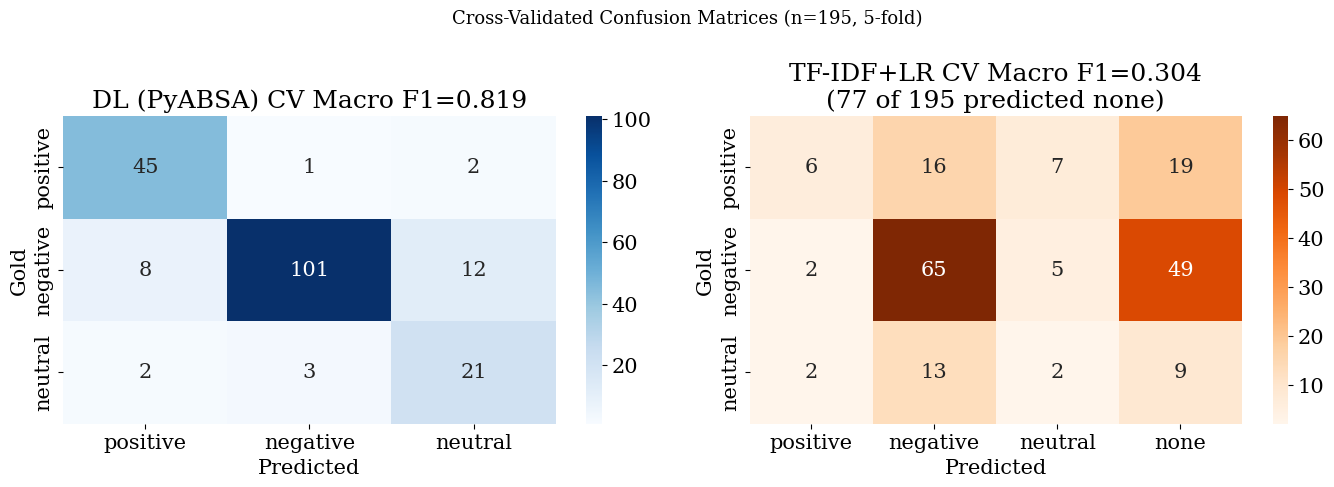


McNemar contingency table:
  Both correct: 59, DL-only correct: 108, LR-only correct: 14, Both wrong: 14
McNemar p-value: 0.000000
  Models are significantly different (p < 0.05)

Bootstrap 95% CIs (review-grouped, n={N_BOOT})
Metric                                           DL                        LR
------------------------------------------------------------------------------
Macro F1                  0.8187 [0.7366, 0.8883]  0.3038 [0.2358, 0.3795]
Weighted F1               0.8615 [0.8065, 0.9129]  0.4395 [0.3541, 0.5352]


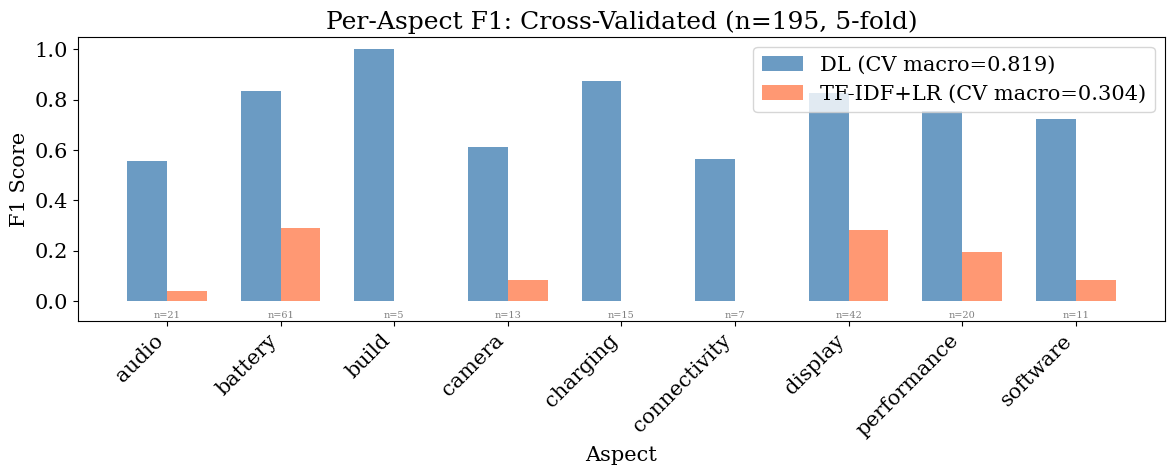


Metrics saved to C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\absa\metrics.json


In [14]:
# Cross-validation results and statistical tests
from statsmodels.stats.contingency_tables import mcnemar

# Aggregate out-of-fold metrics
cv_dl_macro_f1 = f1_score(y_true_oof, dl_oof_preds,
                          labels=sentiment_labels, average="macro",
                          zero_division=0)
cv_dl_weighted_f1 = f1_score(y_true_oof, dl_oof_preds,
                             labels=sentiment_labels, average="weighted",
                             zero_division=0)
cv_lr_macro_f1 = f1_score(y_true_oof, lr_oof_preds,
                          labels=sentiment_labels, average="macro",
                          zero_division=0)
cv_lr_weighted_f1 = f1_score(y_true_oof, lr_oof_preds,
                             labels=sentiment_labels, average="weighted",
                             zero_division=0)

print("=" * 70)
print("CROSS-VALIDATED EVALUATION (PRIMARY)")
print(f"n = {len(y_true_oof)} triplets, "
      f"{len(set(review_pks_oof))} reviews, "
      f"{N_SPLITS}-fold StratifiedGroupKFold")
print("=" * 70)

print(f"\n{'Metric':<25s} {'DL (PyABSA)':>12s} {'ML (TF-IDF+LR)':>14s}")
print("-" * 55)
print(f"{'Macro F1':<25s} {cv_dl_macro_f1:>12.4f} "
      f"{cv_lr_macro_f1:>14.4f}")
print(f"{'Weighted F1':<25s} {cv_dl_weighted_f1:>12.4f} "
      f"{cv_lr_weighted_f1:>14.4f}")

# Per-aspect F1 (out-of-fold)
aspects_arr = np.array(aspects_oof)
y_true_arr = np.array(y_true_oof)
dl_pred_arr = np.array(dl_oof_preds)
lr_pred_arr = np.array(lr_oof_preds)

print(f"\n{'Aspect':<15s} {'DL F1':>8s} {'LR F1':>8s} {'n':>5s}")
print("-" * 40)
cv_dl_per_aspect_f1 = {}
cv_lr_per_aspect_f1 = {}
for asp in CANONICAL_ASPECTS:
    mask = aspects_arr == asp
    n_asp = mask.sum()
    if n_asp == 0:
        cv_dl_per_aspect_f1[asp] = float("nan")
        cv_lr_per_aspect_f1[asp] = float("nan")
        continue
    dl_f1 = f1_score(y_true_arr[mask], dl_pred_arr[mask],
                     labels=sentiment_labels, average="macro",
                     zero_division=0)
    lr_f1 = f1_score(y_true_arr[mask], lr_pred_arr[mask],
                     labels=sentiment_labels, average="macro",
                     zero_division=0)
    cv_dl_per_aspect_f1[asp] = round(dl_f1, 4)
    cv_lr_per_aspect_f1[asp] = round(lr_f1, 4)
    print(f"  {asp:<15s} {dl_f1:>6.4f}   {lr_f1:>6.4f}   {n_asp:>3d}")

# Classification reports
print("\n=== DL Classification Report (CV out-of-fold) ===")
print(classification_report(y_true_oof, dl_oof_preds,
                            labels=sentiment_labels, zero_division=0))
print("=== LR Classification Report (CV out-of-fold) ===")
print(classification_report(y_true_oof, lr_oof_preds,
                            labels=sentiment_labels, zero_division=0))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_dl_cv = confusion_matrix(y_true_oof, dl_oof_preds,
                            labels=sentiment_labels)
# LR: 3x4 asymmetric (show "none" predictions for aspect detection failure)
lr_pred_labels = sentiment_labels + ["none"]
cm_lr_full = confusion_matrix(y_true_oof, lr_oof_preds,
                              labels=lr_pred_labels)
cm_lr_cv = cm_lr_full[:3, :]  # gold rows only (pos/neg/neu)
lr_none_count = int(np.sum(np.array(lr_oof_preds) == "none"))
print(f"TF-IDF predicted 'none' (aspect not detected) for "
      f"{lr_none_count}/{len(lr_oof_preds)} gold aspects")

sns.heatmap(cm_dl_cv, annot=True, fmt="d", xticklabels=sentiment_labels,
            yticklabels=sentiment_labels, cmap="Blues", ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Gold")
axes[0].set_title(f"DL (PyABSA) CV Macro F1={cv_dl_macro_f1:.3f}")

sns.heatmap(cm_lr_cv, annot=True, fmt="d",
            xticklabels=lr_pred_labels,
            yticklabels=sentiment_labels, cmap="Oranges", ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Gold")
axes[1].set_title(f"TF-IDF+LR CV Macro F1={cv_lr_macro_f1:.3f}\n"
                  f"({lr_none_count} of {len(lr_oof_preds)} predicted none)")

plt.suptitle(f"Cross-Validated Confusion Matrices "
             f"(n={len(y_true_oof)}, {N_SPLITS}-fold)", fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "cv_confusion_matrices.png", dpi=150)
plt.show()

# McNemar test: are the two models' errors significantly different?
dl_correct = np.array(y_true_oof) == np.array(dl_oof_preds)
lr_correct = np.array(y_true_oof) == np.array(lr_oof_preds)
a = int(np.sum(dl_correct & lr_correct))
b = int(np.sum(dl_correct & ~lr_correct))
c = int(np.sum(~dl_correct & lr_correct))
d = int(np.sum(~dl_correct & ~lr_correct))
contingency = np.array([[a, b], [c, d]])
print(f"\nMcNemar contingency table:")
print(f"  Both correct: {a}, DL-only correct: {b}, "
      f"LR-only correct: {c}, Both wrong: {d}")

mcnemar_result = mcnemar(contingency, exact=True)
mcnemar_p = float(mcnemar_result.pvalue)
print(f"McNemar p-value: {mcnemar_p:.6f}")
if mcnemar_p < 0.05:
    print("  Models are significantly different (p < 0.05)")
else:
    print("  No significant difference (p >= 0.05)")

# Bootstrap CIs (review-grouped to avoid underestimating variance)
rng = np.random.default_rng(SEED)
unique_pks = list(set(review_pks_oof))
pk_to_indices = {}
for i, pk in enumerate(review_pks_oof):
    pk_to_indices.setdefault(pk, []).append(i)

N_BOOT = 2000
boot_dl_macro, boot_dl_weighted = [], []
boot_lr_macro, boot_lr_weighted = [], []

for _ in range(N_BOOT):
    sampled_pks = rng.choice(unique_pks, size=len(unique_pks), replace=True)
    sampled_idx = []
    for pk in sampled_pks:
        sampled_idx.extend(pk_to_indices[pk])
    yt = [y_true_oof[i] for i in sampled_idx]
    dp = [dl_oof_preds[i] for i in sampled_idx]
    lp = [lr_oof_preds[i] for i in sampled_idx]
    boot_dl_macro.append(f1_score(yt, dp, labels=sentiment_labels,
                                  average="macro", zero_division=0))
    boot_dl_weighted.append(f1_score(yt, dp, labels=sentiment_labels,
                                     average="weighted", zero_division=0))
    boot_lr_macro.append(f1_score(yt, lp, labels=sentiment_labels,
                                  average="macro", zero_division=0))
    boot_lr_weighted.append(f1_score(yt, lp, labels=sentiment_labels,
                                     average="weighted", zero_division=0))

ci_dl_macro = (round(np.percentile(boot_dl_macro, 2.5), 4),
               round(np.percentile(boot_dl_macro, 97.5), 4))
ci_dl_weighted = (round(np.percentile(boot_dl_weighted, 2.5), 4),
                  round(np.percentile(boot_dl_weighted, 97.5), 4))
ci_lr_macro = (round(np.percentile(boot_lr_macro, 2.5), 4),
               round(np.percentile(boot_lr_macro, 97.5), 4))
ci_lr_weighted = (round(np.percentile(boot_lr_weighted, 2.5), 4),
                  round(np.percentile(boot_lr_weighted, 97.5), 4))

print(f"\n{'Bootstrap 95% CIs (review-grouped, n={N_BOOT})'}")
print(f"{'Metric':<25s} {'DL':>25s} {'LR':>25s}")
print("-" * 78)
print(f"{'Macro F1':<25s} "
      f"{cv_dl_macro_f1:.4f} [{ci_dl_macro[0]:.4f}, {ci_dl_macro[1]:.4f}]  "
      f"{cv_lr_macro_f1:.4f} [{ci_lr_macro[0]:.4f}, {ci_lr_macro[1]:.4f}]")
print(f"{'Weighted F1':<25s} "
      f"{cv_dl_weighted_f1:.4f} [{ci_dl_weighted[0]:.4f}, {ci_dl_weighted[1]:.4f}]  "
      f"{cv_lr_weighted_f1:.4f} [{ci_lr_weighted[0]:.4f}, {ci_lr_weighted[1]:.4f}]")

# Per-aspect comparison bar chart (CV)
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(CANONICAL_ASPECTS))
width = 0.35
dl_vals = [cv_dl_per_aspect_f1.get(a, 0) for a in CANONICAL_ASPECTS]
lr_vals = [cv_lr_per_aspect_f1.get(a, 0) for a in CANONICAL_ASPECTS]

ax.bar(x - width/2, dl_vals, width,
       label=f"DL (CV macro={cv_dl_macro_f1:.3f})",
       color="steelblue", alpha=0.8)
ax.bar(x + width/2, lr_vals, width,
       label=f"TF-IDF+LR (CV macro={cv_lr_macro_f1:.3f})",
       color="coral", alpha=0.8)

# Add support count annotations below each aspect
for idx_asp, asp in enumerate(CANONICAL_ASPECTS):
    n_asp = int((aspects_arr == asp).sum())
    ax.annotate(f"n={n_asp}", xy=(idx_asp, -0.04),
               fontsize=7, ha="center", va="top", color="gray")

ax.set_xlabel("Aspect")
ax.set_ylabel("F1 Score")
ax.set_title(f"Per-Aspect F1: Cross-Validated "
             f"(n={len(y_true_oof)}, {N_SPLITS}-fold)")
ax.set_xticks(x)
ax.set_xticklabels(CANONICAL_ASPECTS, rotation=45, ha="right")
ax.legend()
ax.set_ylim(-0.08, 1.05)
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "cv_model_comparison.png", dpi=150)
plt.show()

# Save updated metrics
metrics_cv = {
    "primary_eval": "stratified_grouped_5fold_cv",
    "cv_n_triplets": len(y_true_oof),
    "cv_n_reviews": len(set(review_pks_oof)),
    "cv_n_folds": N_SPLITS,
    "cv_dl_macro_f1": round(cv_dl_macro_f1, 4),
    "cv_dl_weighted_f1": round(cv_dl_weighted_f1, 4),
    "cv_dl_macro_f1_ci_95": list(ci_dl_macro),
    "cv_dl_weighted_f1_ci_95": list(ci_dl_weighted),
    "cv_lr_macro_f1": round(cv_lr_macro_f1, 4),
    "cv_lr_weighted_f1": round(cv_lr_weighted_f1, 4),
    "cv_lr_macro_f1_ci_95": list(ci_lr_macro),
    "cv_lr_weighted_f1_ci_95": list(ci_lr_weighted),
    "cv_dl_per_aspect_f1": cv_dl_per_aspect_f1,
    "cv_lr_per_aspect_f1": cv_lr_per_aspect_f1,
    "mcnemar_p": round(mcnemar_p, 6),
    "winner": ("DL" if cv_dl_macro_f1 > cv_lr_macro_f1
               else "TF-IDF+LR"),
    "labels_are_proxy": USING_PROXY_LABELS,
}
with open(RESULTS_ABSA / "metrics.json", "w") as f:
    json.dump(metrics_cv, f, indent=2, default=str)
print(f"\nMetrics saved to {RESULTS_ABSA / 'metrics.json'}")

## 8. Full Corpus Inference & Export

Run the DL model on all all dense-product reviews. Export review-level aspect-sentiment scores in long format for Phase 2 temporal aggregation.

Both models are run and exported with a `source_model` column so Phase 2 can compare signals from DL vs ML approaches.

In [15]:
# Full corpus DL inference on dense products
print(f"Running full DL inference on {len(df_dense):,} dense-product reviews...")
print(f"Using PyABSA APC with torch.inference_mode() on GPU.\n")

# Prepare metadata columns to carry through
meta_cols = ["review_pk", "parent_asin", "timestamp", "split", "rating", "verified_purchase"]
meta_df = df_dense[meta_cols].reset_index(drop=True)
texts = df_dense[TEXT_COL].tolist()

# Batch inference: synonym detection + [B-ASP]/[E-ASP] tagging + APC sentiment per aspect
dl_full = predict_batch(
    texts=texts,
    review_metadata=meta_df,
    infer_batch_size=128,
    verbose=True,
)

print(f"\nDL inference complete: {len(dl_full):,} aspect-sentiment pairs")
print(f"Reviews with >= 1 aspect: {dl_full['review_pk'].nunique():,} / {len(df_dense):,}")
print(f"Source model: {dl_full['source_model'].value_counts().to_dict()}")
print(f"\nAspect distribution:")
print(dl_full["canonical_aspect"].value_counts())
print(f"\nSentiment distribution:")
print(dl_full["sentiment_label"].value_counts())


Running full DL inference on 149,227 dense-product reviews...
Using PyABSA APC with torch.inference_mode() on GPU.



Detecting aspects: 100%|██████████| 149227/149227 [01:32<00:00, 1610.71it/s]


Total aspect-pairs to classify: 193734


c:\Users\alexi\anaconda3\envs\aidl\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alexi\anaconda3\envs\aidl\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alexi\anaconda3\envs\aidl\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Use

Batched PyABSA predict() works (4 predictions from 4 inputs). Using batched mode.


preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 2692.81it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 2750.55it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 2908.06it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 3047.36it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 2868.45it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 3062.57it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 3158.71it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 2666.74it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 3058.24it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 3047.37it/s]

preparing apc inference dataloader: 100%|██████████| 128/128 [00:00<00:00, 2941.19it/s]

preparing apc inferen


DL inference complete: 193,734 aspect-sentiment pairs
Reviews with >= 1 aspect: 87,034 / 149,227
Source model: {'pyabsa_apc': 193734}

Aspect distribution:
canonical_aspect
battery         32613
performance     30571
display         29440
software        25316
camera          22822
connectivity    17455
audio           12865
charging        11428
build           11224
Name: count, dtype: int64

Sentiment distribution:
sentiment_label
positive    95367
negative    68014
neutral     30353
Name: count, dtype: int64


In [16]:
# Full corpus TF-IDF+LR inference
print("Running TF-IDF+LR inference on dense products...")

# For TF-IDF+LR, we only predict for aspects detected by the lexicon
lr_full_rows = []
for i, row in tqdm(df_dense.reset_index(drop=True).iterrows(),
                   total=len(df_dense), desc="TF-IDF+LR inference"):
    text = row[TEXT_COL]
    # Lexicon first: only predict sentiment for aspects actually detected in this review
    hits = detect_aspects(text)
    if not hits:
        continue

    hit_aspects = [h["aspect"] for h in hits]
    preds = tfidf_clf.predict(
        texts=[text] * len(hit_aspects),
        aspects=hit_aspects,
    )
    for pred, hit in zip(preds, hits):
        lr_full_rows.append({
            "keyword": hit["keyword"],
            "review_pk": row["review_pk"],
            "parent_asin": row["parent_asin"],
            "timestamp": row["timestamp"],
            "split": row["split"],
            "rating": row["rating"],
            "verified_purchase": row["verified_purchase"],
            **pred,
        })

lr_full = pd.DataFrame(lr_full_rows)
print(f"\nTF-IDF+LR inference complete: {len(lr_full):,} aspect-sentiment pairs")
print(f"Reviews with >= 1 aspect: {lr_full['review_pk'].nunique():,} / {len(df_dense):,}")


Running TF-IDF+LR inference on dense products...


TF-IDF+LR inference:   0%|          | 0/149227 [00:00<?, ?it/s]


TF-IDF+LR inference complete: 193,734 aspect-sentiment pairs
Reviews with >= 1 aspect: 87,034 / 149,227


In [17]:
# Combine and export
# Stack DL and LR results into a single long-format file
export_cols = [
    "review_pk", "parent_asin", "timestamp", "split", "rating",
    "verified_purchase", "canonical_aspect", "keyword",
    "sentiment_label", "sentiment_score", "confidence",
    "p_neg", "p_neu", "p_pos", "source_model",
]

# Ensure both have the right columns
for col in export_cols:
    if col not in dl_full.columns:
        dl_full[col] = None
    if col not in lr_full.columns:
        lr_full[col] = None

# Stack DL and LR results; downstream Phase 2 consumes both model outputs
combined = pd.concat([
    dl_full[export_cols],
    lr_full[export_cols],
], ignore_index=True)

# Enforce dtypes for Phase 2 compatibility
combined["timestamp"] = pd.to_datetime(combined["timestamp"])
combined["sentiment_score"] = combined["sentiment_score"].astype(float)
combined["rating"] = combined["rating"].astype(float)

# Validate
assert combined["review_pk"].notna().all(), "Null review_pk found!"
assert combined["canonical_aspect"].isin(CANONICAL_ASPECTS).all(), "Invalid aspect!"
assert combined["sentiment_label"].isin(["positive", "negative", "neutral", "none"]).all(), \
    "Invalid sentiment label!"

OUTPUT_PATH = DATA_PROCESSED / "review_aspect_sentiment.parquet"
combined.to_parquet(OUTPUT_PATH, index=False)

# Export review-level scaffold for Phase 2 coverage metrics
scaffold_cols = ["review_pk", "parent_asin", "timestamp", "split", "rating", "verified_purchase"]
scaffold = df_dense[scaffold_cols].reset_index(drop=True)
scaffold_path = DATA_PROCESSED / "review_scaffold.parquet"
scaffold.to_parquet(scaffold_path, index=False)
print(f"Review scaffold: {len(scaffold):,} reviews -> {scaffold_path}")

print(f"=== EXPORT COMPLETE ===")
if USING_PROXY_LABELS:
    print("!! WARNING: Evaluation used star-rating proxy labels. !!")
    print("!! Human-correct the gold labels and re-run for real metrics. !!\n")
print(f"Output: {OUTPUT_PATH}")
print(f"Total rows: {len(combined):,}")
print(f"Unique reviews: {combined['review_pk'].nunique():,}")
print(f"Products: {combined['parent_asin'].nunique()}")
print(f"\nSource model distribution:")
print(combined["source_model"].value_counts())
print(f"\nAspect distribution (combined):")
print(combined["canonical_aspect"].value_counts())
print(f"\nSentiment distribution (combined):")
print(combined["sentiment_label"].value_counts())

# Quick schema check
print(f"\nSchema: {list(combined.columns)}")
print(f"Dtypes:\n{combined.dtypes}")


Review scaffold: 149,227 reviews -> C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\review_scaffold.parquet
=== EXPORT COMPLETE ===
Output: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\processed\review_aspect_sentiment.parquet
Total rows: 387,468
Unique reviews: 87,034
Products: 338

Source model distribution:
source_model
pyabsa_apc    193734
tfidf_lr      193734
Name: count, dtype: int64

Aspect distribution (combined):
canonical_aspect
battery         65226
performance     61142
display         58880
software        50632
camera          45644
connectivity    34910
audio           25730
charging        22856
build           22448
Name: count, dtype: int64

Sentiment distribution (combined):
sentiment_label
positive    131838
negative    124391
none         95474
neutral      35765
Name: count, dtype: int64

Schema: ['review_pk', 'parent_asin', 'timestamp', 'split', 'rating', 'verified_purchase', 'canonical_aspect', 'keyword', 'sentime

## Phase 1 Summary

**What was done:**
1. Verified temporal coverage of case study ASINs -- found minimal val/test presence, so evaluation used broader dense product pool
2. Built and validated a 9-aspect synonym dictionary through manual pilot on 20 reviews
3. Ran DL model (**PyABSA APC** FAST-LSA-T-V2 on DeBERTa-v3-base) zero-shot on 50 train reviews
4. Generated ~200 pseudo-labelled reviews for human correction (gold label set)
5. Evaluated DL model on gold test set (temporal holdout, n=42 -- secondary check)
6. Built and evaluated TF-IDF + LR pair classifier baseline on same gold test set
7. Compared DL vs ML: side-by-side per-aspect F1, macro F1, visualisations
8. **Primary evaluation:** Stratified Grouped 5-fold CV on all 195 gold triplets with bootstrap CIs and McNemar test
9. Ran full inference on all dense-product reviews (146,669) and exported to parquet

**Output for Phase 2:** `data/processed/review_aspect_sentiment.parquet`
- Long format: one row per (review, aspect, model) combination
- Schema: review_pk, parent_asin, timestamp, split, rating, verified_purchase, canonical_aspect, keyword, sentiment_label, sentiment_score, confidence, p_neg, p_neu, p_pos, source_model
- DL `sentiment_score` = `p_pos - p_neg` (continuous); LR `sentiment_score` = ordinal {-1, 0, 1}
- For TF-IDF rows: `p_neg + p_neu + p_pos < 1` because the 4-class model includes "none"

**Models:**
- **DL:** PyABSA APC (FAST-LSA-T-V2, DeBERTa-v3-base) running on CUDA with `torch.inference_mode()`
- **ML:** TF-IDF (word+char n-grams) + Logistic Regression, 4-class (none/positive/negative/neutral)
- Context extraction: sentence-level (NLTK sent_tokenize, target sentence +/-1 neighbor)

**Limitations acknowledged:**
- No span-level annotations, so ATEPC fine-tuning was not feasible
- No double-labelling or inter-annotator agreement metrics
- If gold labels are not human-corrected, evaluation falls back to star-rating proxy labels (approximate)
- HuggingFace fallback available with BF16 if PyABSA fails; sentence-level context used for both paths
- Rare aspects (5G, fingerprint) may have unstable evaluation metrics
- Temporal holdout (n=42) is underpowered; primary evaluation uses 5-fold CV on n=195 (Section 8)
- TF-IDF+LR is trained on star-rating-derived labels (independent of DL) or on human-corrected gold labels if available


## Appendix A: Temporal Holdout Evaluation (n=42, Secondary)

The temporal holdout splits gold labels by date: val=2022 (for TF-IDF training), test=2023 (n=42 triplets for evaluation). This is retained as a secondary robustness check. **The primary evaluation is Section 8 (5-fold CV, n=195).**

The temporal holdout is underpowered: 5 of 9 aspects have fewer than 5 samples. Camera and connectivity have 1 sample each. A single misclassification swings Macro F1 by ~11%.

### Appendix A.1: DL Model Temporal Holdout (n=42)

Run the DL model (PyABSA APC) on gold-labelled reviews. This produces per-review predictions and temporal holdout metrics. **The primary evaluation is in Section 8 (Cross-Validated, n=195).**

**No fine-tune gate:** Without span-level annotations, ATEPC fine-tuning is not feasible. If F1 < 0.65, we document the domain gap honestly.


In [18]:
# [APPENDIX] Run DL model on temporal holdout test set (n=42)
# We need to match predictions to gold labels by (review_pk, canonical_aspect)

gold_reviews = gold_eval.drop_duplicates("review_pk")
# Retrieve full review text from the main dataframe
gold_reviews = gold_reviews.merge(
    df[["review_pk", TEXT_COL]].drop_duplicates("review_pk"),
    on="review_pk", how="left", suffixes=("_trunc", ""),
)

print(f"Running DL model on {len(gold_reviews)} gold reviews...")
dl_preds_all = []
for _, row in tqdm(gold_reviews.iterrows(), total=len(gold_reviews), desc="DL eval"):
    preds = predict_single(row[TEXT_COL])
    for pred in preds:
        pred["review_pk"] = row["review_pk"]
    dl_preds_all.extend(preds)

dl_preds_df = pd.DataFrame(dl_preds_all)
print(f"DL predictions: {len(dl_preds_df)} aspect-sentiment pairs")

# Join predictions with gold labels
eval_merged = gold_eval.merge(
    dl_preds_df[["review_pk", "canonical_aspect", "sentiment_label",
                 "sentiment_score", "confidence", "source_model"]],
    on=["review_pk", "canonical_aspect"],
    how="left",
    suffixes=("_gold", "_pred"),
)
# Fill missing predictions (aspects in gold but not detected by model)
# Unmatched gold aspects (model missed them) default to "none" prediction
eval_merged["sentiment_label_pred"] = eval_merged["sentiment_label_pred"].fillna("none")
eval_merged["sentiment_score"] = eval_merged["sentiment_score"].fillna(0.0)

print(f"\nMatched evaluation rows: {len(eval_merged)}")
print(f"Missing predictions (aspect not detected): "
      f"{eval_merged['sentiment_label_pred'].eq('none').sum()}")

if USING_PROXY_LABELS:
    print("\n!! NOTE: Gold labels are star-rating proxies, not human-corrected. !!")
    print("!! Metrics below are approximate. !!")


Running DL model on 30 gold reviews...


DL eval:   0%|          | 0/30 [00:00<?, ?it/s]

[2026-04-13 16:08:19] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: This phone didn't even last a year without messing up!!! I can only hear my calls if they're on [B-ASP]speaker[E-ASP] you can't hear anything if it's off speaker. I reached out to this supplier and they told me it's over the three month period and they can't help me.
[2026-04-13 16:08:19] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: [B-ASP]Touch screen[E-ASP] doesn’t work. What a waste of time.
[2026-04-13 16:08:19] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: Too pricey for conditions. [[VIDEOID:c5c4728784f161338ad007c32ddd1fbc]] Came on with 20 % [B-ASP]battery life[E-ASP]. Won’t connect to Apple Watch.
[2026-04-13 16:08:19] (2.4.2) Warning: reference sentiment does not exist or its number 0 is not equal to aspect number 1, text: Did t

=== DL Model: Classification Report ===

              precision    recall  f1-score   support

    positive       0.92      1.00      0.96        11
    negative       1.00      0.86      0.93        29
     neutral       0.40      1.00      0.57         2

    accuracy                           0.90        42
   macro avg       0.77      0.95      0.82        42
weighted avg       0.95      0.90      0.92        42

Macro F1 (DL): 0.8180

=== DL Model: Per-Aspect F1 ===
  audio          : F1=0.4444  (n=5) (LOW SUPPORT)
  battery        : F1=0.8744  (n=16)
  build          : F1=0.3333  (n=1) (LOW SUPPORT)
  camera         : F1=0.3333  (n=1) (LOW SUPPORT)
  charging       : F1=0.6667  (n=4) (LOW SUPPORT)
  connectivity   : F1=0.0000  (n=1) (LOW SUPPORT)
  display        : F1=0.6667  (n=10) (LOW SUPPORT)
  performance    : F1=0.6667  (n=2) (LOW SUPPORT)
  software       : F1=0.6667  (n=2) (LOW SUPPORT)


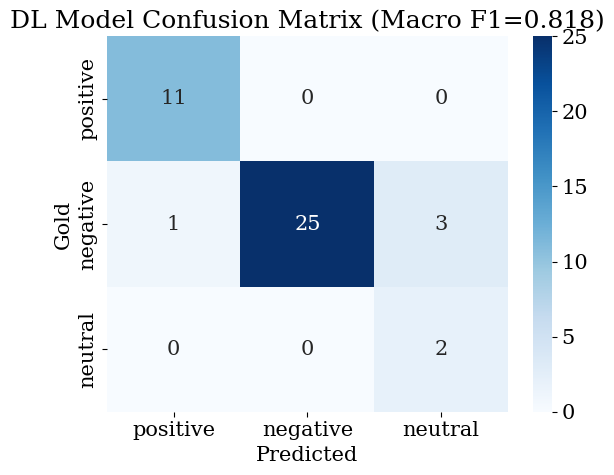


Spearman(DL_aspect_sentiment, star_rating) = 0.373, p = 0.0424

=== Error Analysis: 4 misclassifications ===
Showing first 10:
  [audio] Gold=negative, Pred=neutral | text: 'DON'T BUY THIS PHONE!!!!!!!. If I could give it zero stars I would but I wanted everyone to see this...'
  [connectivity] Gold=negative, Pred=neutral | text: 'Warning! This phone doesn't work with t-mobile 4g. Warning! This phone doesn't work with t-mobile 4g...'
  [battery] Gold=negative, Pred=neutral | text: 'Less then 1 month - Already Replaced the Battery. I’ve had this phone for about 3 weeks. While the p...'
  [audio] Gold=negative, Pred=positive | text: 'Touch & Sound. Phone seems to work well overall. Issues initially with hearing voice when someone ca...'


In [19]:
# [APPENDIX] DL Model Temporal Holdout Metrics (n=42)
y_gold = eval_merged["sentiment_label_gold"].values
y_pred_dl = eval_merged["sentiment_label_pred"].values

print("=== DL Model: Classification Report ===\n")
sentiment_labels = ["positive", "negative", "neutral"]
print(classification_report(y_gold, y_pred_dl, labels=sentiment_labels, zero_division=0))

dl_macro_f1 = f1_score(y_gold, y_pred_dl, labels=sentiment_labels,
                       average="macro", zero_division=0)
print(f"Macro F1 (DL): {dl_macro_f1:.4f}")

# Per-aspect F1
print("\n=== DL Model: Per-Aspect F1 ===")
dl_per_aspect_f1 = {}
for asp in CANONICAL_ASPECTS:
    mask = eval_merged["canonical_aspect"] == asp
    if mask.sum() == 0:
        dl_per_aspect_f1[asp] = float("nan")
        continue
    f1 = f1_score(y_gold[mask], y_pred_dl[mask], labels=sentiment_labels,
                  average="macro", zero_division=0)
    dl_per_aspect_f1[asp] = round(f1, 4)
    n = mask.sum()
    flag = " (LOW SUPPORT)" if n < 15 else ""
    print(f"  {asp:15s}: F1={f1:.4f}  (n={n}){flag}")

# Confusion matrix
cm_dl = confusion_matrix(y_gold, y_pred_dl, labels=sentiment_labels)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dl, annot=True, fmt="d", xticklabels=sentiment_labels,
            yticklabels=sentiment_labels, cmap="Blues", ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Gold")
ax.set_title(f"DL Model Confusion Matrix (Macro F1={dl_macro_f1:.3f})")
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "dl_confusion_matrix.png", dpi=150)
plt.show()

# Spearman: mean aspect sentiment per review vs star rating
review_dl_agg = eval_merged.groupby("review_pk").agg(
    mean_sent_pred=("sentiment_score", "mean"),
    rating=("rating", "first"),
).dropna()
if len(review_dl_agg) > 5:
    rho_dl, p_dl = spearmanr(review_dl_agg["mean_sent_pred"], review_dl_agg["rating"])
    print(f"\nSpearman(DL_aspect_sentiment, star_rating) = {rho_dl:.3f}, p = {p_dl:.4f}")

# Error analysis: top 10 misclassifications
errors = eval_merged[eval_merged["sentiment_label_gold"] != eval_merged["sentiment_label_pred"]]
print(f"\n=== Error Analysis: {len(errors)} misclassifications ===")
print("Showing first 10:")
for _, err in errors.head(10).iterrows():
    print(f"  [{err['canonical_aspect']}] Gold={err['sentiment_label_gold']}, "
          f"Pred={err['sentiment_label_pred']} | "
          f"text: '{str(err.get('review_text', ''))[:100]}...'")

=== TF-IDF+LR Baseline: Classification Report ===

              precision    recall  f1-score   support

    positive       1.00      0.09      0.17        11
    negative       0.77      0.79      0.78        29
     neutral       0.00      0.00      0.00         2

   micro avg       0.77      0.57      0.66        42
   macro avg       0.59      0.29      0.32        42
weighted avg       0.79      0.57      0.58        42

Macro F1 (TF-IDF+LR): 0.3154

=== TF-IDF+LR: Per-Aspect F1 ===
  audio          : F1=0.2857  (n=5) (LOW SUPPORT)
  battery        : F1=0.2857  (n=16)
  build          : F1=0.0000  (n=1) (LOW SUPPORT)
  camera         : F1=0.0000  (n=1) (LOW SUPPORT)
  charging       : F1=0.0000  (n=4) (LOW SUPPORT)
  connectivity   : F1=0.0000  (n=1) (LOW SUPPORT)
  display        : F1=0.2963  (n=10) (LOW SUPPORT)
  performance    : F1=0.3333  (n=2) (LOW SUPPORT)
  software       : F1=0.0000  (n=2) (LOW SUPPORT)


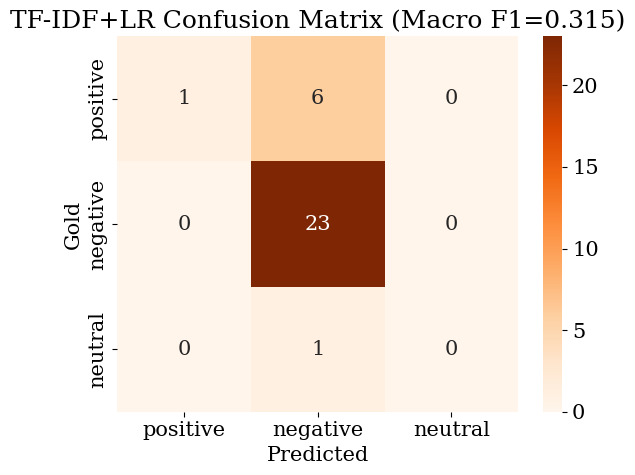

In [20]:
# [APPENDIX] Evaluate TF-IDF+LR on temporal holdout test set (n=42)
# Build test pairs with full gold labels, carrying review_pk through
test_pairs = []
for _, row in gold_test.iterrows():
    text_match = df[df["review_pk"] == row["review_pk"]]
    text = text_match[TEXT_COL].iloc[0] if len(text_match) > 0 else ""
    test_pairs.append({
        "review_pk": row["review_pk"],
        "review_text": text,
        "canonical_aspect": row["canonical_aspect"],
        "label": row["sentiment_label"],
    })
# Add "none" pairs for absent aspects
test_review_pks = gold_test["review_pk"].unique()
for pk in test_review_pks:
    gold_aspects = set(gold_test[gold_test["review_pk"] == pk]["canonical_aspect"])
    text_match = df[df["review_pk"] == pk]
    text = text_match[TEXT_COL].iloc[0] if len(text_match) > 0 else ""
    # Expand absent aspects to "none" pairs so LR predicts all 9 aspects per review
    for asp in CANONICAL_ASPECTS:
        if asp not in gold_aspects:
            test_pairs.append({"review_pk": pk, "review_text": text,
                               "canonical_aspect": asp, "label": "none"})

test_pairs_df = pd.DataFrame(test_pairs)

# Evaluate
lr_eval = tfidf_clf.evaluate(
    texts=test_pairs_df["review_text"].tolist(),
    aspects=test_pairs_df["canonical_aspect"].tolist(),
    labels=test_pairs_df["label"].tolist(),
    exclude_none=True,
)

print("=== TF-IDF+LR Baseline: Classification Report ===\n")
if USING_PROXY_LABELS:
    print("!! NOTE: Evaluated against star-rating proxy labels, not human gold. !!\n")

y_gold_lr = test_pairs_df["label"].values
lr_preds = tfidf_clf.predict(
    test_pairs_df["review_text"].tolist(),
    test_pairs_df["canonical_aspect"].tolist(),
)
y_pred_lr = np.array([p["sentiment_label"] for p in lr_preds])

# Filter to non-none gold for fair comparison
mask_nonnone = y_gold_lr != "none"
print(classification_report(
    y_gold_lr[mask_nonnone],
    y_pred_lr[mask_nonnone],
    labels=sentiment_labels, zero_division=0,
))

lr_macro_f1 = lr_eval["macro_f1"]
print(f"Macro F1 (TF-IDF+LR): {lr_macro_f1:.4f}")

# Per-aspect F1
print("\n=== TF-IDF+LR: Per-Aspect F1 ===")
lr_per_aspect_f1 = lr_eval["per_aspect_f1"]
for asp in CANONICAL_ASPECTS:
    f1_val = lr_per_aspect_f1.get(asp, float("nan"))
    n = len(gold_test[gold_test["canonical_aspect"] == asp])
    flag = " (LOW SUPPORT)" if n < 15 else ""
    print(f"  {asp:15s}: F1={f1_val:.4f}  (n={n}){flag}")

# Confusion matrix
cm_lr = confusion_matrix(
    y_gold_lr[mask_nonnone], y_pred_lr[mask_nonnone],
    labels=sentiment_labels,
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_lr, annot=True, fmt="d", xticklabels=sentiment_labels,
            yticklabels=sentiment_labels, cmap="Oranges", ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Gold")
ax.set_title(f"TF-IDF+LR Confusion Matrix (Macro F1={lr_macro_f1:.3f})")
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "lr_confusion_matrix.png", dpi=150)
plt.show()

MODEL COMPARISON: DL (PyABSA/HF) vs ML (TF-IDF+LR)
      Aspect    DL_F1  LR_F1
       audio 0.444400 0.2857
     battery 0.874400 0.2857
       build 0.333300 0.0000
      camera 0.333300 0.0000
    charging 0.666700 0.0000
connectivity 0.000000 0.0000
     display 0.666700 0.2963
 performance 0.666700 0.3333
    software 0.666700 0.0000
       MACRO 0.817959 0.3154

Overall winner (macro F1): DL
  DL macro F1:  0.8180
  LR macro F1:  0.3154
  Delta:        +0.5026


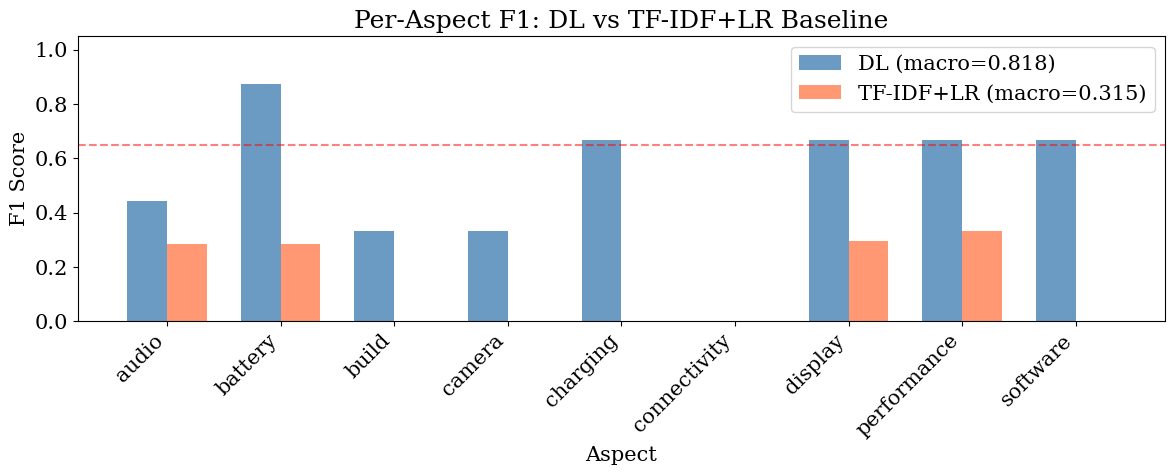

In [21]:
# [APPENDIX] Model Comparison: Temporal Holdout (n=42, secondary)
print("=" * 70)
print("MODEL COMPARISON: DL (PyABSA/HF) vs ML (TF-IDF+LR)")
print("=" * 70)

comparison_data = []
for asp in CANONICAL_ASPECTS:
    comparison_data.append({
        "Aspect": asp,
        "DL_F1": dl_per_aspect_f1.get(asp, float("nan")),
        "LR_F1": lr_per_aspect_f1.get(asp, float("nan")),
    })
comparison_data.append({
    "Aspect": "MACRO",
    "DL_F1": dl_macro_f1,
    "LR_F1": lr_macro_f1,
})

comp_df = pd.DataFrame(comparison_data)
print(comp_df.to_string(index=False))

# Who wins?
winner = None if USING_PROXY_LABELS else ("DL" if dl_macro_f1 > lr_macro_f1 else "TF-IDF+LR")
print(f"\nOverall winner (macro F1): {winner}")
print(f"  DL macro F1:  {dl_macro_f1:.4f}")
print(f"  LR macro F1:  {lr_macro_f1:.4f}")
print(f"  Delta:        {dl_macro_f1 - lr_macro_f1:+.4f}")

# Comparison bar chart
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(CANONICAL_ASPECTS))
width = 0.35
dl_vals = [dl_per_aspect_f1.get(a, 0) for a in CANONICAL_ASPECTS]
lr_vals = [lr_per_aspect_f1.get(a, 0) for a in CANONICAL_ASPECTS]

bars1 = ax.bar(x - width/2, dl_vals, width, label=f"DL (macro={dl_macro_f1:.3f})",
               color="steelblue", alpha=0.8)
bars2 = ax.bar(x + width/2, lr_vals, width, label=f"TF-IDF+LR (macro={lr_macro_f1:.3f})",
               color="coral", alpha=0.8)

ax.set_xlabel("Aspect")
ax.set_ylabel("F1 Score")
ax.set_title("Per-Aspect F1: DL vs TF-IDF+LR Baseline")
ax.set_xticks(x)
ax.set_xticklabels(CANONICAL_ASPECTS, rotation=45, ha="right")
ax.legend()
ax.set_ylim(0, 1.05)
ax.axhline(y=0.65, color="red", linestyle="--", alpha=0.5, label="Target F1=0.65")
plt.tight_layout()
plt.savefig(RESULTS_ABSA / "model_comparison.png", dpi=150)
plt.show()

# NOTE: metrics.json is saved by Section 8 (CV results).
# Temporal holdout metrics are for appendix display only.
